# Solution: Matplotlib — Swiss EV Charging Stations

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('../ev_charging_stations.csv')
print('Shape:', df.shape)

Shape: (2442, 15)


### Task 1 — Histogram of `power_kw`

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df['power_kw'], bins=30, color='steelblue', edgecolor='white')
ax.set_xlabel('Charging Power (kW)')
ax.set_ylabel('Number of Stations')
ax.set_title('Distribution of Charging Power')
plt.tight_layout()
plt.show()

### Task 2 — Horizontal bar chart: top 10 cities

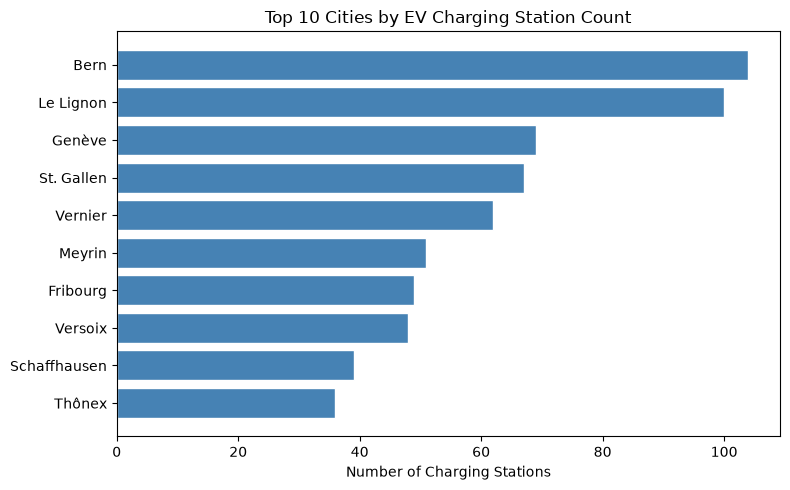

In [ ]:
top10 = df['city'].value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top10.index, top10.values, color='steelblue', edgecolor='white')
ax.set_xlabel('Number of Charging Stations')
ax.set_title('Top 10 Cities by EV Charging Station Count')
plt.tight_layout()
plt.show()

### Task 3 — Box plot: `power_kw` by `power_type`

In [ ]:
order = ['AC_1_PHASE', 'AC_3_PHASE', 'DC']
data = [df[df['power_type'] == t]['power_kw'].values for t in order]

fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot(data, tick_labels=order, patch_artist=True,
           boxprops=dict(facecolor='steelblue', alpha=0.6))
ax.set_xlabel('Power Type')
ax.set_ylabel('Charging Power (kW)')
ax.set_title('Charging Power by Power Type')
plt.tight_layout()
plt.show()

### Task 4 — Scatter plot: `voltage` vs. `power_kw` coloured by `power_type`

In [ ]:
colors = {'AC_1_PHASE': 'green', 'AC_3_PHASE': 'steelblue', 'DC': 'tomato'}

fig, ax = plt.subplots(figsize=(8, 5))
for ptype, grp in df.groupby('power_type'):
    ax.scatter(grp['voltage'], grp['power_kw'],
               label=ptype, color=colors[ptype], alpha=0.5, s=20)
ax.set_xlabel('Voltage (V)')
ax.set_ylabel('Charging Power (kW)')
ax.set_title('Voltage vs. Charging Power by Power Type')
ax.legend()
plt.tight_layout()
plt.show()

### Task 5 — Pie chart: share of `plug_type`

In [ ]:
counts = df['plug_type'].value_counts()
top4 = counts.head(4)
other = counts.iloc[4:].sum()
if other > 0:
    top4['Other'] = other

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(top4.values, labels=top4.index, autopct='%1.1f%%', startangle=90)
ax.set_title('Share of Plug Types')
plt.tight_layout()
plt.show()

### Task 6 — Combined 2×2 subplot figure

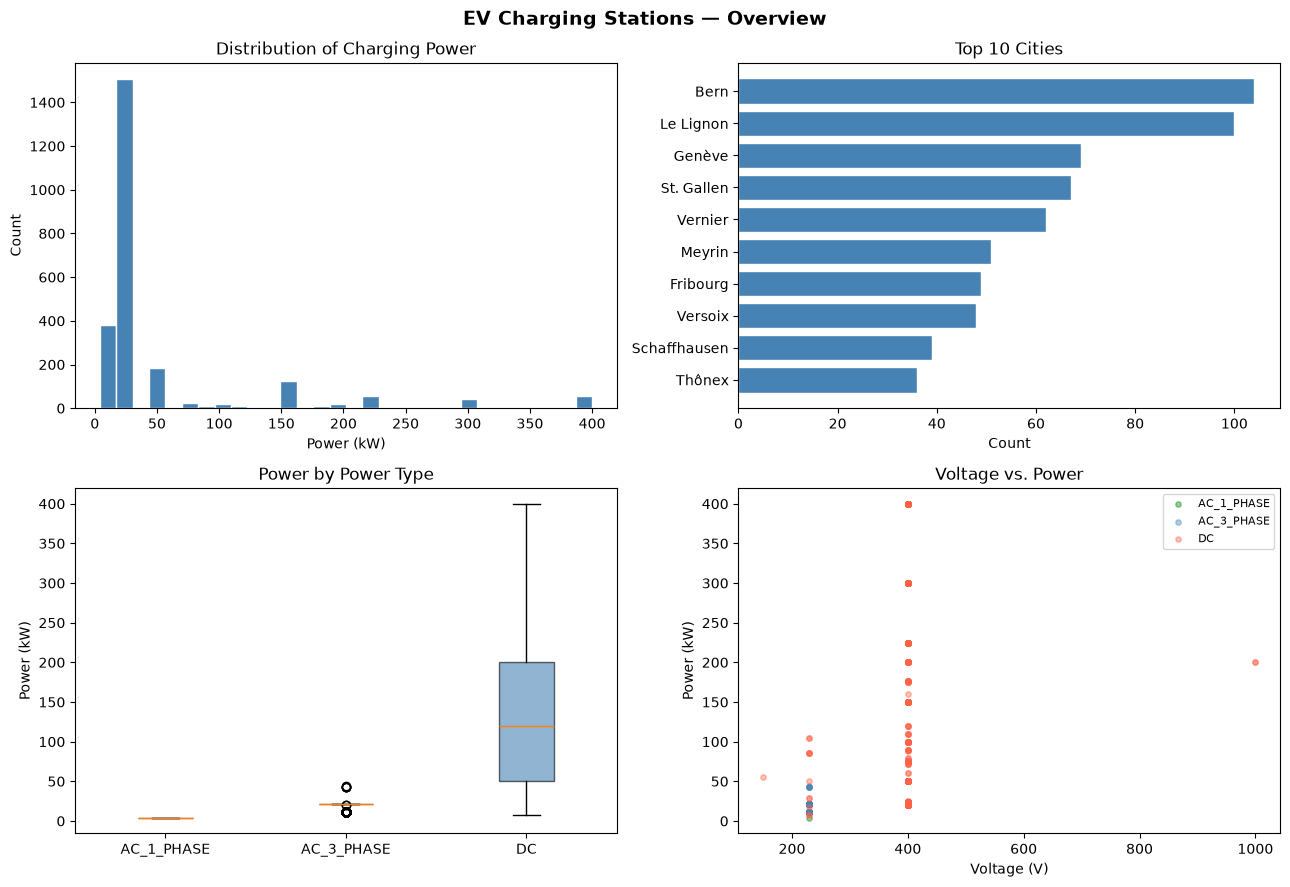

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))                                 #Abbildung mit 2 Zeilen und 2 Spalten (= 4 Diagramme) erstellen
                                                                                #fig: Gesamte Abbildung; axes: 2×2-Array mit vier Zeichenflächen
                                                                                #figsize: Gesamtgrösse in Zoll

# Histogram
axes[0, 0].hist(df['power_kw'], bins=30, color='steelblue', edgecolor='white')  #Histogramm oben links: Ladeleistung in 30 Intervalle unterteilen
axes[0, 0].set_title('Distribution of Charging Power')                          #Titel des ersten Diagramms
axes[0, 0].set_xlabel('Power (kW)')                                             #X-Achse: Ladeleistung
axes[0, 0].set_ylabel('Count')                                                  #Y-Achse: Häufigkeit

# Bar chart
top10 = df['city'].value_counts().head(10).sort_values()                        #10 häufigste Städte ermitteln und aufsteigend sortieren
axes[0, 1].barh(top10.index, top10.values, color='steelblue', edgecolor='white') #Balkendiagramm oben rechts: Städte (Y) und Häufigkeiten (X)
axes[0, 1].set_title('Top 10 Cities')                                           #Titel des zweiten Diagramms
axes[0, 1].set_xlabel('Count')                                                  #X-Achse: Anzahl Ladestationen

# Box plot
order = ['AC_1_PHASE', 'AC_3_PHASE', 'DC']                                      #Reihenfolge der Ladearten festlegen
data = [df[df['power_type'] == t]['power_kw'].values for t in order]            #Ladeleistungen je Ladeart als separate Arrays zusammenstellen
                                                                                #List Comprehension: Daten nach jeder Kategorie filtern
axes[1, 0].boxplot(data, tick_labels=order, patch_artist=True,                  #Boxplots unten links: Verteilung der Ladeleistung je Ladeart
                   boxprops=dict(facecolor='steelblue', alpha=0.6))             #Boxen füllen (patch_artist=True); Farbe und Transparenz festlegen
axes[1, 0].set_title('Power by Power Type')                                     #Titel des dritten Diagramms
axes[1, 0].set_ylabel('Power (kW)')                                             #Y-Achse: Ladeleistung

# Scatter plot
colors = {'AC_1_PHASE': 'green', 'AC_3_PHASE': 'steelblue', 'DC': 'tomato'}     #Jeder Ladeart eine Farbe zuweisen
for ptype, grp in df.groupby('power_type'):                                     #Daten nach Ladeart gruppieren; ptype = Kategorie, grp = zugehörige Daten
    axes[1, 1].scatter(grp['voltage'], grp['power_kw'],                         #Scatter Plot unten rechts: Spannung (X) gegen Ladeleistung (Y)
                       label=ptype, color=colors[ptype], alpha=0.4, s=15)       #Legendenname, Farbe, Transparenz und Punktgrösse
axes[1, 1].set_title('Voltage vs. Power')                                       #Titel des vierten Diagramms
axes[1, 1].set_xlabel('Voltage (V)')                                            #X-Achse: Spannung
axes[1, 1].set_ylabel('Power (kW)')                                             #Y-Achse: Ladeleistung
axes[1, 1].legend(fontsize=8)                                                   #Legende mit Ladearten anzeigen; Schriftgrösse 8

fig.suptitle('EV Charging Stations — Overview', fontsize=14, fontweight='bold') #Übergeordneter Titel für alle vier Diagramme
plt.tight_layout()                                                              #Abstände zwischen Diagrammen und Beschriftungen optimieren
plt.show()                                                                      #Gesamte Abbildung mit allen vier Diagrammen anzeigen

#ANPASSEN: df und die Spalten 'power_kw', 'city', 'power_type' und 'voltage' an den Datensatz anpassen
#ANPASSEN: order und colors an die vorhandenen Kategorien anpassen
#ANPASSEN: bins=30, head(10), figsize, Farben, Transparenz und Punktgrössen bei Bedarf anpassen
#ANPASSEN: Titel und Achsenbeschriftungen der einzelnen Diagramme passend wählen
#ANPASSEN: plt.subplots(2, 2) ändern, falls eine andere Anzahl Diagramme benötigt wird
#NICHTS ANPASSEN: Die grundsätzliche Vorgehensweise mit plt.subplots(), axes[Zeile, Spalte], plt.tight_layout() und plt.show()
#VORAUSSETZUNG: matplotlib.pyplot wurde als plt importiert und df ist geladen
#ACHTUNG: Die Indizierung beginnt bei 0 → axes[0, 0] = oben links; axes[1, 1] = unten rechts
#ACHTUNG: Bei einer anderen Subplot-Anordnung müssen die axes-Indizes entsprechend angepasst werden
#ERKENNTNIS: Subplots ermöglichen den direkten Vergleich mehrerer Diagramme innerhalb einer einzigen Figure

## Jupyter notebook --footer info--
(please always provide this at the end of each notebook)

In [ ]:
import os, platform, socket
from platform import python_version
from datetime import datetime
print('------------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Python Version:', python_version())
print('------------------------------------')